In [2]:
import sys
import numpy as np

print("Python:", sys.version.split()[0])
print("Ejecutable:", sys.executable)
print("NumPy:", np.__version__)
print("Jupyter funcionando correctamente")

Python: 3.12.10
Ejecutable: c:\ProyectoRiesgoCrediticio\.venv\Scripts\python.exe
NumPy: 2.5.3
Jupyter funcionando correctamente


# Auditoría del modelo de riesgo crediticio

## Proyecto de clasificación mediante KNN

Este cuaderno presenta la evaluación del clasificador K-Nearest Neighbors (KNN), desarrollado con Python y NumPy para analizar el riesgo crediticio.

Se utiliza el conjunto de datos South German Credit, que contiene 1.000 registros.

### Objetivos de la auditoría

- Evaluar el rendimiento del modelo mediante una matriz de confusión.
- Calcular exactitud, precisión, recall y F1-Score.
- Analizar la equidad de las predicciones según grupos de edad.
- Calcular el indicador Disparate Impact.
- Comparar la exactitud y los falsos negativos entre grupos.

### Configuración del modelo

| Parámetro | Valor |
|---|---|
| Algoritmo | K-Nearest Neighbors |
| Vecinos | K = 5 |
| Entrenamiento después del IQR | 732 registros |
| Prueba | 200 registros |
| Características procesadas | 62 |
| Clase 0 | Mal crédito |
| Clase 1 | Buen crédito |
| División de datos | 80 % entrenamiento / 20 % prueba |

**Nota:** El preprocesamiento se ajusta utilizando exclusivamente los datos de entrenamiento para evitar fuga de información.


| Parámetro | Valor |
|---|---|
| Algoritmo | K-Nearest Neighbors |
| Vecinos | K = 5 |
| Entrenamiento después del IQR | 732 registros |
| Prueba | 200 registros |
| Características procesadas | 62 |
| Clase 0 | Mal crédito |
| Clase 1 | Buen crédito |
| División de datos | 80 % entrenamiento / 20 % prueba |

**Nota:** El preprocesamiento se ajusta utilizando exclusivamente los datos de entrenamiento para evitar fuga de información.

In [3]:
from auditoria.metricas import (calcular_matriz_confusion,calcular_metricas)

print("Funciones de evaluación importadas correctamente")

Funciones de evaluación importadas correctamente


In [4]:
from pathlib import Path

ruta_dataset = Path("datos/SouthGermanCredit.asc")
with ruta_dataset.open("r", encoding="utf-8") as archivo: lineas = archivo.readlines()
columnas = lineas[0].strip().split()
registros = tuple(tuple(map(int, linea.split())) for linea in lineas[1:] if linea.strip())

print("Dataset cargado correctamente")
print("Total de registros:", len(registros))
print("Total de columnas:", len(columnas))
print("Primer registro:", registros[0])
print("Estructura inmutable:", isinstance(registros, tuple))

Dataset cargado correctamente
Total de registros: 1000
Total de columnas: 21
Primer registro: (1, 18, 4, 2, 1049, 1, 2, 4, 2, 1, 4, 2, 21, 3, 1, 1, 3, 2, 1, 2, 1)
Estructura inmutable: True


In [5]:
from ingesta.division import dividir_datos
from ingesta.preprocesamiento import preparar_datos
from ingesta.limpieza import simular_ausentes

registros_prueba = simular_ausentes(registros)

print("*** SIMULACION DE VALORES AUSENTES ***")
print("Registros originales:", len(registros))
print("Registros experimentales:", len(registros_prueba))

entrenamiento, prueba = dividir_datos(registros_prueba, proporcion = 0.8, semilla = 42)

print("\n*** DIVISION DE DATOS ***")
print("Entrenamiento original:", len(entrenamiento))
print("Prueba original:", len(prueba))

entrenamiento_procesado, prueba_procesada = preparar_datos(entrenamiento, prueba, columna = 4)

print("\n*** PREPROCESAMIENTO ***")
print("Entrenamiento procesado:", len(entrenamiento_procesado))
print("Prueba procesada:", len(prueba_procesada))
print("Total original:", len(registros))

*** SIMULACION DE VALORES AUSENTES ***
Registros originales: 1000
Registros experimentales: 1000

*** DIVISION DE DATOS ***
Entrenamiento original: 800
Prueba original: 200

*** PREPROCESAMIENTO ***
Entrenamiento procesado: 732
Prueba procesada: 200
Total original: 1000


In [6]:
from modelo.datos import separar_caracteristicas_etiquetas

X_train, y_train = separar_caracteristicas_etiquetas(entrenamiento_procesado)
X_test, y_test = separar_caracteristicas_etiquetas(prueba_procesada)

print("*** MATRICES NUMPY ***")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\n*** VERIFICACIONES ***")
print("Características por registro:", X_train.shape[1])
print("Clases existentes:", np.unique(y_train))
print("Total de registros de prueba:", len(y_test))

*** MATRICES NUMPY ***
X_train: (732, 20)
y_train: (732,)
X_test: (200, 20)
y_test: (200,)

*** VERIFICACIONES ***
Características por registro: 20
Clases existentes: [0 1]
Total de registros de prueba: 200


In [7]:
from modelo.caracteristicas import (
    obtener_categorias, 
    codificar_one_hot, 
    obtener_limites_numericos,
    normalizar_numericas,
    unir_caracteristicas
)

categorias = obtener_categorias(X_train)
X_train_categorico = codificar_one_hot(X_train, categorias)
X_test_categorico = codificar_one_hot(X_test, categorias)
minimos, maximos = obtener_limites_numericos(X_train)
X_train_numerico = normalizar_numericas(X_train, minimos, maximos)
X_test_numerico = normalizar_numericas(X_test, minimos, maximos)
X_train_final = unir_caracteristicas(X_train_numerico, X_train_categorico)
X_test_final = unir_caracteristicas(X_test_numerico, X_test_categorico)

print("*** CARACTERISTICAS DEFINITIVAS PARA KNN ***")
print("Variables numéricas:", X_train_numerico.shape[1])
print("Columnas One-Hot:", X_train_categorico.shape[1])
print("")
print("*** MATRICES FINALES ***")
print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)
print("")
print("*** VERIFICACIONES ***")
print("Mismas columnas:", X_train_final.shape[1] == X_test_final.shape[1])
print("Valores ausentes entrenamiento:", np.isnan(X_train_final).sum())
print("Valores ausentes prueba:", np.isnan(X_test_final).sum())

*** CARACTERISTICAS DEFINITIVAS PARA KNN ***
Variables numéricas: 6
Columnas One-Hot: 56

*** MATRICES FINALES ***
X_train_final: (732, 62)
X_test_final: (200, 62)

*** VERIFICACIONES ***
Mismas columnas: True
Valores ausentes entrenamiento: 0
Valores ausentes prueba: 0


In [8]:
from modelo.knn import predecir_knn

predicciones = predecir_knn(
    X_train_final,
    y_train,
    X_test_final,
    k = 5
)

print("*** PREDICCIONES KNN ***")
print("Valor de K:", 5)
print("Total de predicciones:", len(predicciones))
print("")
print("Primeras 10 predicciones:")
print(predicciones[:10])
print("Primeras 10 etiquetas reales:")
print(y_test[:10])
print("")
print("*** DISTRIBUCION DE PREDICCIONES ***")
print("Clase 0 - Mal credito:", np.sum(predicciones == 0))
print("Clase 1 - Buen credito:", np.sum(predicciones == 1))
print("")
print("Forma del resultado:", predicciones.shape)

*** PREDICCIONES KNN ***
Valor de K: 5
Total de predicciones: 200

Primeras 10 predicciones:
[1 1 1 1 1 1 1 0 1 1]
Primeras 10 etiquetas reales:
[0 1 1 1 0 1 1 0 0 0]

*** DISTRIBUCION DE PREDICCIONES ***
Clase 0 - Mal credito: 34
Clase 1 - Buen credito: 166

Forma del resultado: (200,)


In [9]:
matriz_confusion = calcular_matriz_confusion(y_test, predicciones)
metricas = calcular_metricas(matriz_confusion)

print("*** MATRIZ DE CONFUSION KNN ***")
print(matriz_confusion)
print("")
print("*** DETALLE DE CLASIFICACION ***")
print("Verdaderos positivos:", matriz_confusion[0, 0])
print("Falsos negativos:", matriz_confusion[0, 1])
print("Falsos positivos:", matriz_confusion[1, 0])
print("Verdaderos negativos:", matriz_confusion[1, 1])
print("")
print("*** METRICAS DE EVALUACION ***")
print(f"Exactitud: {metricas['exactitud']:.2%}")
print(f"Precision: {metricas['precision']:.2%}")
print(f"Recall: {metricas['recall']:.2%}")
print(f"F1-Score: {metricas['f1']:.2%}")
print("")
print("Total evaluado:", np.sum(matriz_confusion))


*** MATRIZ DE CONFUSION KNN ***
[[ 16  49]
 [ 18 117]]

*** DETALLE DE CLASIFICACION ***
Verdaderos positivos: 16
Falsos negativos: 49
Falsos positivos: 18
Verdaderos negativos: 117

*** METRICAS DE EVALUACION ***
Exactitud: 66.50%
Precision: 47.06%
Recall: 24.62%
F1-Score: 32.32%

Total evaluado: 200


In [10]:
from auditoria.equidad import calcular_disparate_impact

edades = X_test[:, 12]
resultado_equidad = calcular_disparate_impact(edades,predicciones)

print("*** AUDITORIA DE EQUIDAD KNN ***")
print(resultado_equidad)

*** AUDITORIA DE EQUIDAD KNN ***
{'total_a': 21, 'total_b': 179, 'favorables_a': 16, 'favorables_b': 150, 'tasa_a': np.float64(0.7619047619047619), 'tasa_b': np.float64(0.8379888268156425), 'disparate_impact': np.float64(0.9092063492063491)}


In [11]:
from auditoria.equidad import calcular_exactitud_por_grupo

resultado_exactitud = calcular_exactitud_por_grupo(edades, y_test, predicciones)

print("*** EXACTITUD POR GRUPOS DE EDAD ***")
print("")
print("Grupo A - Menores de 25 años")
print("Total:", resultado_exactitud["total_a"])
print("Predicciones correctas:", resultado_exactitud["correctas_a"])
print(f"Exactitud: {resultado_exactitud['exactitud_a']:.2%}")
print("")
print("Grupo B - 25 años o más")
print("Total:", resultado_exactitud["total_b"])
print("Predicciones correctas:", resultado_exactitud["correctas_b"])
print(f"Exactitud: {resultado_exactitud['exactitud_b']:.2%}")
print("")
print("*** VERIFICACION GENERAL ***")
total_correctas = (resultado_exactitud["correctas_a"] + resultado_exactitud["correctas_b"])
print("Total de predicciones correctas:", total_correctas)
print("Coincide con matriz de confusión:", total_correctas == np.trace(matriz_confusion))

*** EXACTITUD POR GRUPOS DE EDAD ***

Grupo A - Menores de 25 años
Total: 21
Predicciones correctas: 15
Exactitud: 71.43%

Grupo B - 25 años o más
Total: 179
Predicciones correctas: 118
Exactitud: 65.92%

*** VERIFICACION GENERAL ***
Total de predicciones correctas: 133
Coincide con matriz de confusión: True


In [12]:
from auditoria.equidad import calcular_falsos_negativos_por_grupo

resultado_fn = calcular_falsos_negativos_por_grupo(
    edades,
    y_test,
    predicciones
)

print("*** FALSOS NEGATIVOS POR GRUPO DE EDAD ***")
print("")
print("Grupo A - Menores de 25 años")
print("Casos reales de mal crédito:", resultado_fn["malos_a"])
print("Falsos negativos:", resultado_fn["fn_a"])
print(f"Tasa FN: {resultado_fn['tasa_fn_a']:.2%}")
print("")
print("\nGrupo B - 25 años o más")
print("Casos reales de mal crédito:", resultado_fn["malos_b"])
print("Falsos negativos:", resultado_fn["fn_b"])
print(f"Tasa FN: {resultado_fn['tasa_fn_b']:.2%}")
print("")
print("*** VERIFICACION GENERAL ***")
total_fn = resultado_fn["fn_a"] + resultado_fn["fn_b"]
print("Total de falsos negativos:", total_fn)
print("Coincide con matriz de confusión:", total_fn == matriz_confusion[0, 1])

*** FALSOS NEGATIVOS POR GRUPO DE EDAD ***

Grupo A - Menores de 25 años
Casos reales de mal crédito: 9
Falsos negativos: 5
Tasa FN: 55.56%


Grupo B - 25 años o más
Casos reales de mal crédito: 56
Falsos negativos: 44
Tasa FN: 78.57%

*** VERIFICACION GENERAL ***
Total de falsos negativos: 49
Coincide con matriz de confusión: True


## Conclusiones de la auditoría del modelo KNN

### 1. Evaluación del rendimiento

El modelo KNN desarrollado con NumPy, utilizando K = 5, obtuvo
una exactitud del 66,50 %, una precisión del 47,06 %, un recall
del 24,62 % y un F1-Score del 32,32 %.

Aunque el modelo clasificó correctamente 133 de los 200 registros
evaluados, presentó dificultades para identificar los casos de
mal crédito, ya que solamente reconoció 16 de los 65 casos reales.

### 2. Evaluación de equidad

Se analizaron dos grupos de edad: personas menores de 25 años
y personas de 25 años o más.

El Disparate Impact obtenido fue de 0,9092, valor que supera
el umbral orientativo de 0,80. Sin embargo, este resultado
por sí solo no garantiza que el modelo sea equitativo.

La exactitud fue del 71,43 % para los menores de 25 años y
del 65,92 % para las personas de 25 años o más.

### 3. Análisis de falsos negativos

La tasa de falsos negativos fue del 55,56 % para el grupo
menor de 25 años y del 78,57 % para el grupo de 25 años o más.

Estos resultados indican que el modelo tiene mayores
dificultades para detectar solicitudes de mal crédito
en el segundo grupo.

También debemos considerar que el grupo de menores de
25 años contiene solamente 21 registros, por lo que
las comparaciones deben interpretarse con precaución.

### 4. Conclusión general

El proyecto permitió implementar un clasificador KNN
mediante operaciones vectorizadas de NumPy, sin utilizar
bibliotecas de aprendizaje automático para el entrenamiento
o la clasificación.

Se aplicó una división reproducible de los datos y
un preprocesamiento basado únicamente en el conjunto
de entrenamiento para evitar fugas de información.

La auditoría permitió comprobar que una exactitud general
aceptable no necesariamente implica una buena detección
de los casos de riesgo ni un comportamiento equivalente
entre diferentes grupos de población.

Por tanto, el modelo cumple una finalidad académica,
pero requiere mejoras y validaciones adicionales antes
de considerarse adecuado para decisiones crediticias reales.

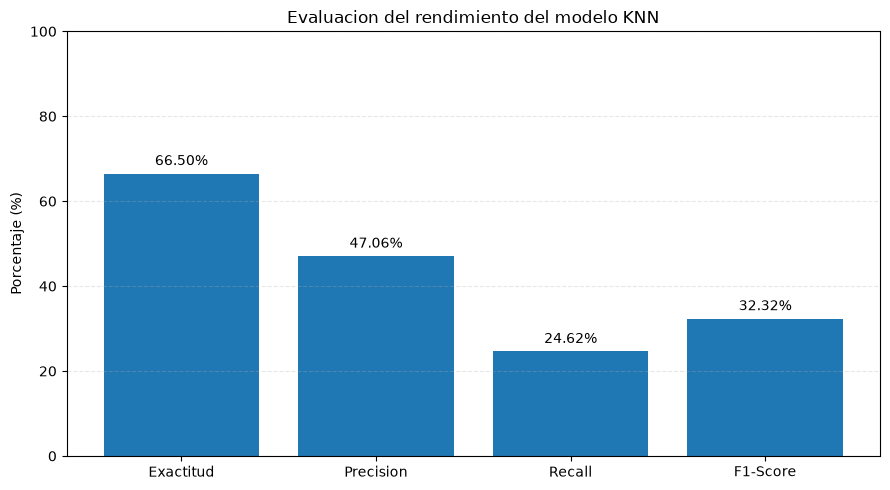

In [13]:
# Gráfico: Métricas del modelo
import matplotlib.pyplot as plt

nombres = ["Exactitud", "Precision", "Recall", "F1-Score"]
valores = [
    metricas["exactitud"] * 100,
    metricas["precision"] * 100,
    metricas["recall"] * 100,
    metricas["f1"] * 100
]
plt.figure(figsize=(9, 5))
barras = plt.bar(nombres, valores)
plt.title("Evaluacion del rendimiento del modelo KNN")
plt.ylabel("Porcentaje (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)
for barra, valor in zip(barras, valores):
    plt.text(barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 2,
        f"{valor:.2f}%",
        ha="center")
plt.tight_layout()
plt.show()

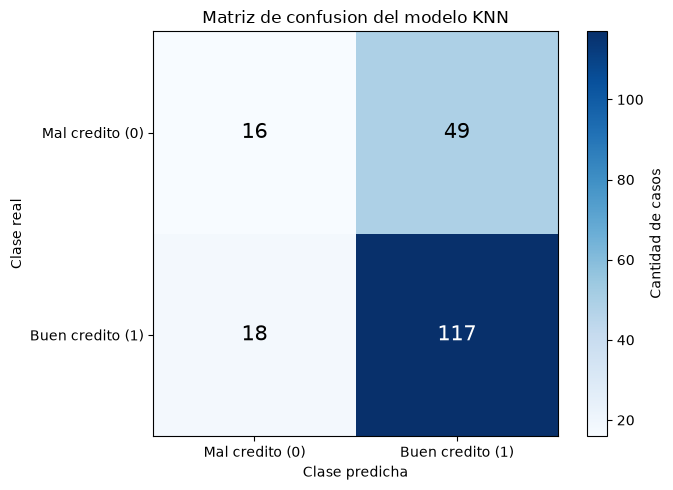

In [14]:
# Grafico: Matriz de confusion del modelo KNN
fig, ax = plt.subplots(figsize=(7, 5))
imagen = ax.imshow(matriz_confusion, cmap="Blues")
clases = ["Mal credito (0)", "Buen credito (1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(clases)
ax.set_yticklabels(clases)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusion del modelo KNN")

for i in range(2):
    for j in range(2):
        valor = matriz_confusion[i, j]
        ax.text(j, i, str(valor), ha="center", va="center", fontsize=15,
            color="white" if valor > matriz_confusion.max() / 2 else "black")
fig.colorbar(imagen, ax=ax, label="Cantidad de casos")
plt.tight_layout()
plt.show()

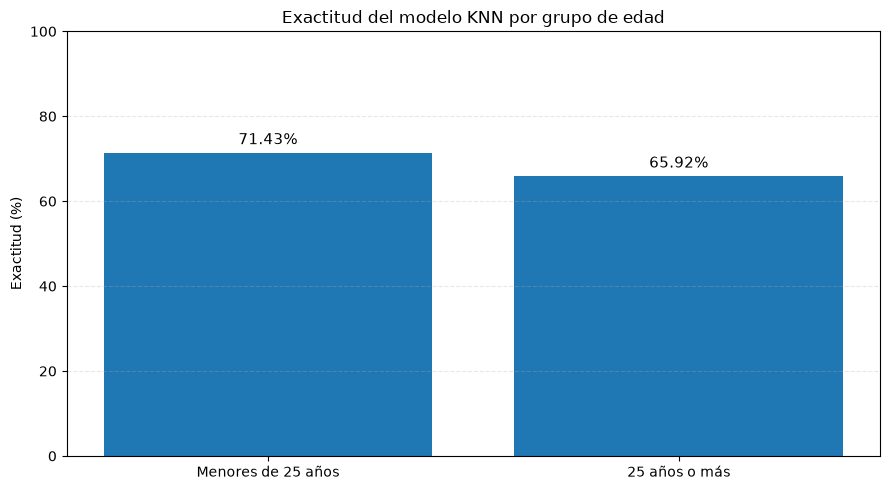

In [15]:
# Gráfico: Exactitud por grupos de edad
grupos = ["Menores de 25 años", "25 años o más"]
exactitudes = [resultado_exactitud["exactitud_a"] * 100,
               resultado_exactitud["exactitud_b"] * 100]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(grupos, exactitudes)
ax.set_title("Exactitud del modelo KNN por grupo de edad")
ax.set_ylabel("Exactitud (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.3)
for barra, valor in zip(barras, exactitudes):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 2,
            f"{valor:.2f}%", ha="center", fontsize=11)
plt.tight_layout()
plt.show()

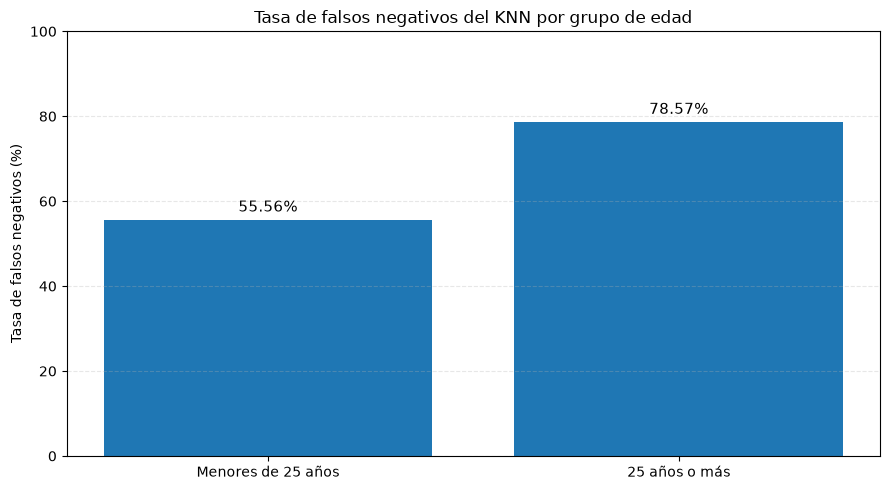

In [16]:
# Grafico: Falsos negativos por grupos de edad
grupos = ["Menores de 25 años", "25 años o más"]
tasas_fn = [resultado_fn["tasa_fn_a"] * 100,
            resultado_fn["tasa_fn_b"] * 100]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(grupos, tasas_fn)
ax.set_title("Tasa de falsos negativos del KNN por grupo de edad")
ax.set_ylabel("Tasa de falsos negativos (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.3)
for barra, valor in zip(barras, tasas_fn):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 2,
            f"{valor:.2f}%", ha="center", fontsize=11)
plt.tight_layout()
plt.show()

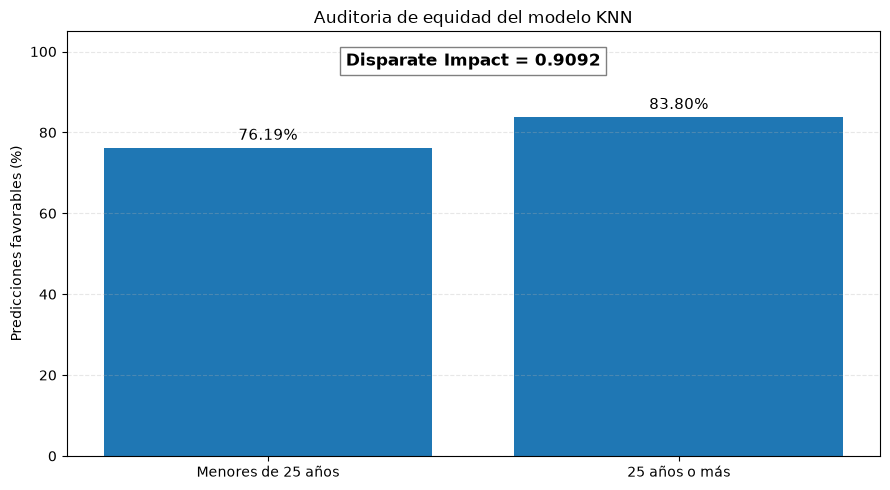

In [17]:
# Grafico: Tasas favorables y Disparate Impact
grupos = ["Menores de 25 años", "25 años o más"]
tasas = [resultado_equidad["tasa_a"] * 100,
         resultado_equidad["tasa_b"] * 100]
di = resultado_equidad["disparate_impact"]
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(grupos, tasas)
ax.set_title("Auditoria de equidad del modelo KNN")
ax.set_ylabel("Predicciones favorables (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.3)
for barra, valor in zip(barras, tasas):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 2,
        f"{valor:.2f}%", ha="center", fontsize=11)
ax.text(0.5, 0.95, f"Disparate Impact = {di:.4f}", transform=ax.transAxes,
        ha="center", va="top", fontsize=12, fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="gray"))
plt.tight_layout()
plt.show()